# Jet engine sensor analysis

NASA's C-MAPSS data (subset FD001) follows 100 simulated jet engines from a healthy state until they fail. Each row is one flight cycle, with 21 sensor readings.

Two questions:

1. Which sensors show that an engine is wearing out, and when do they start to move?
2. From the sensor readings alone, can we estimate how many cycles an engine has left?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

BLUE = "#2a78d6"
ORANGE = "#eb6834"
GREY = "#a3a29c"

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "legend.frameon": False,
})

## 1. Load the data

The files have no header, so the column names come from the NASA documentation. The units in the list are the ones used after the conversion in step 2.

In [2]:
SENSORS = [
    ("T2", "Fan inlet temperature", "°C"),
    ("T24", "LPC outlet temperature", "°C"),
    ("T30", "HPC outlet temperature", "°C"),
    ("T50", "LPT outlet temperature", "°C"),
    ("P2", "Fan inlet pressure", "bar"),
    ("P15", "Bypass duct pressure", "bar"),
    ("P30", "HPC outlet pressure", "bar"),
    ("Nf", "Fan speed", "rpm"),
    ("Nc", "Core speed", "rpm"),
    ("epr", "Engine pressure ratio", "-"),
    ("Ps30", "HPC outlet static pressure", "bar"),
    ("phi", "Fuel flow to Ps30 ratio", "pps/psi"),
    ("NRf", "Corrected fan speed", "rpm"),
    ("NRc", "Corrected core speed", "rpm"),
    ("BPR", "Bypass ratio", "-"),
    ("farB", "Burner fuel-air ratio", "-"),
    ("htBleed", "Bleed enthalpy", "-"),
    ("Nf_dmd", "Demanded fan speed", "rpm"),
    ("PCNfR_dmd", "Demanded corrected fan speed", "rpm"),
    ("W31", "HPT coolant bleed", "lbm/s"),
    ("W32", "LPT coolant bleed", "lbm/s"),
]
all_sensors = [name for name, label, unit in SENSORS]
LABELS = {name: label for name, label, unit in SENSORS}
UNITS = {name: unit for name, label, unit in SENSORS}
COLUMNS = ["engine", "cycle", "setting1", "setting2", "setting3"] + all_sensors

def load(path):
    return pd.read_csv(path, sep=r"\s+", header=None, names=COLUMNS)

train = load("data/train_FD001.txt")
test = load("data/test_FD001.txt")
test_rul = pd.read_csv("data/RUL_FD001.txt", header=None, names=["rul"])["rul"]

life = train.groupby("engine")["cycle"].max()
print(f"Train: {len(train):,} cycles from {train.engine.nunique()} engines")
print(f"Test:  {len(test):,} cycles from {test.engine.nunique()} engines")
print(f"Missing values: {train.isna().sum().sum()}")
print(f"Engine life: {life.min()} to {life.max()} cycles, median {life.median():.0f}")

Train: 20,631 cycles from 100 engines
Test:  13,096 cycles from 100 engines
Missing values: 0
Engine life: 128 to 362 cycles, median 199


## 2. Clean the data

The temperatures are in degrees Rankine and the pressures in psia, which are hard to read. I convert them to °C and bar.

Some sensors never change on this data set, so they carry no information about wear. I drop every sensor that only takes one or two different values.

In [3]:
def convert_units(df):
    df = df.copy()
    for name in ["T2", "T24", "T30", "T50"]:
        df[name] = (df[name] - 491.67) * 5 / 9
    for name in ["P2", "P15", "P30", "Ps30"]:
        df[name] = df[name] * 0.0689476
    return df

train = convert_units(train)
test = convert_units(test)

flat = [s for s in all_sensors if train[s].nunique() <= 2]
sensors = [s for s in all_sensors if s not in flat]
print(f"Dropped {len(flat)} flat sensors: {', '.join(flat)}")
print(f"Kept {len(sensors)} sensors")

Dropped 7 flat sensors: T2, P2, P15, epr, farB, Nf_dmd, PCNfR_dmd
Kept 14 sensors


## 3. Which sensors show wear?

In the training set every engine runs until it fails, so for each row I can compute how many cycles were left before the failure (RUL, remaining useful life). Then I measure how strongly each sensor follows it.

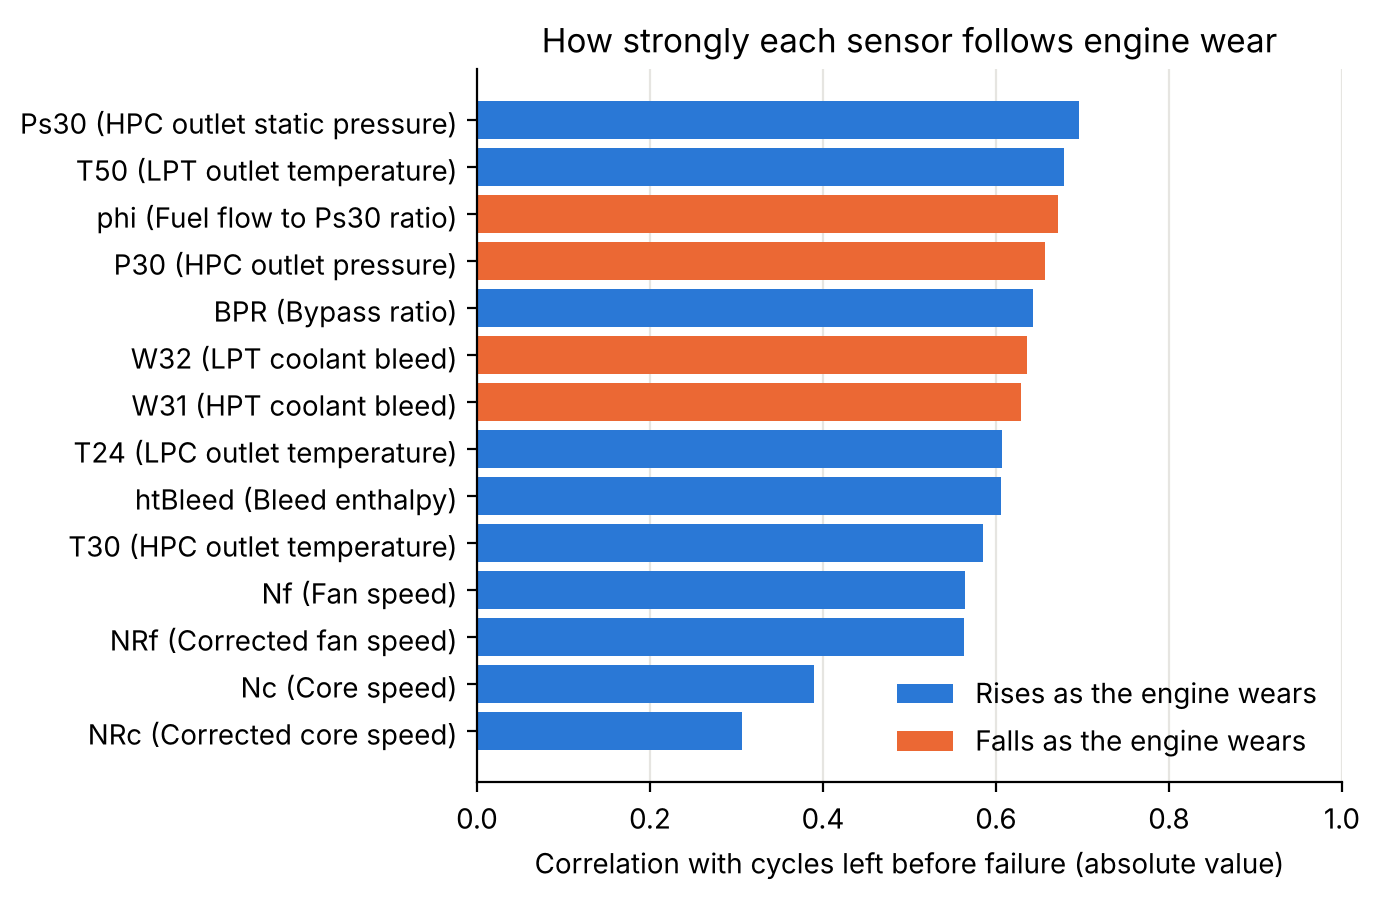

Ps30    0.70
T50     0.68
phi     0.67
P30     0.66
BPR     0.64


In [4]:
train["rul"] = train.groupby("engine")["cycle"].transform("max") - train["cycle"]

corr = train[sensors].corrwith(train["rul"])
table = pd.DataFrame({"sensor": sensors, "strength": corr.abs().values, "rises": (corr < 0).values})
table = table.sort_values("strength").reset_index(drop=True)
rises = table[table.rises]
falls = table[~table.rises]

fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(rises.index, rises.strength, color=BLUE, label="Rises as the engine wears")
ax.barh(falls.index, falls.strength, color=ORANGE, label="Falls as the engine wears")
ax.set_yticks(table.index, [f"{s} ({LABELS[s]})" for s in table.sensor])
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Correlation with cycles left before failure (absolute value)")
ax.set_title("How strongly each sensor follows engine wear")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig("figures/sensor_correlation.png", dpi=150)
plt.show()

top = corr.abs().sort_values(ascending=False).head(5)
print(top.round(2).to_string())

## 4. When do the sensors start to move?

I line the engines up on their failure point (cycle 0 = failure) and plot the three sensors that follow wear most closely and have a physical unit. The thin grey lines are five single engines (1, 25, 50, 75 and 100) and the blue line is the average of all engines at the same distance from failure.

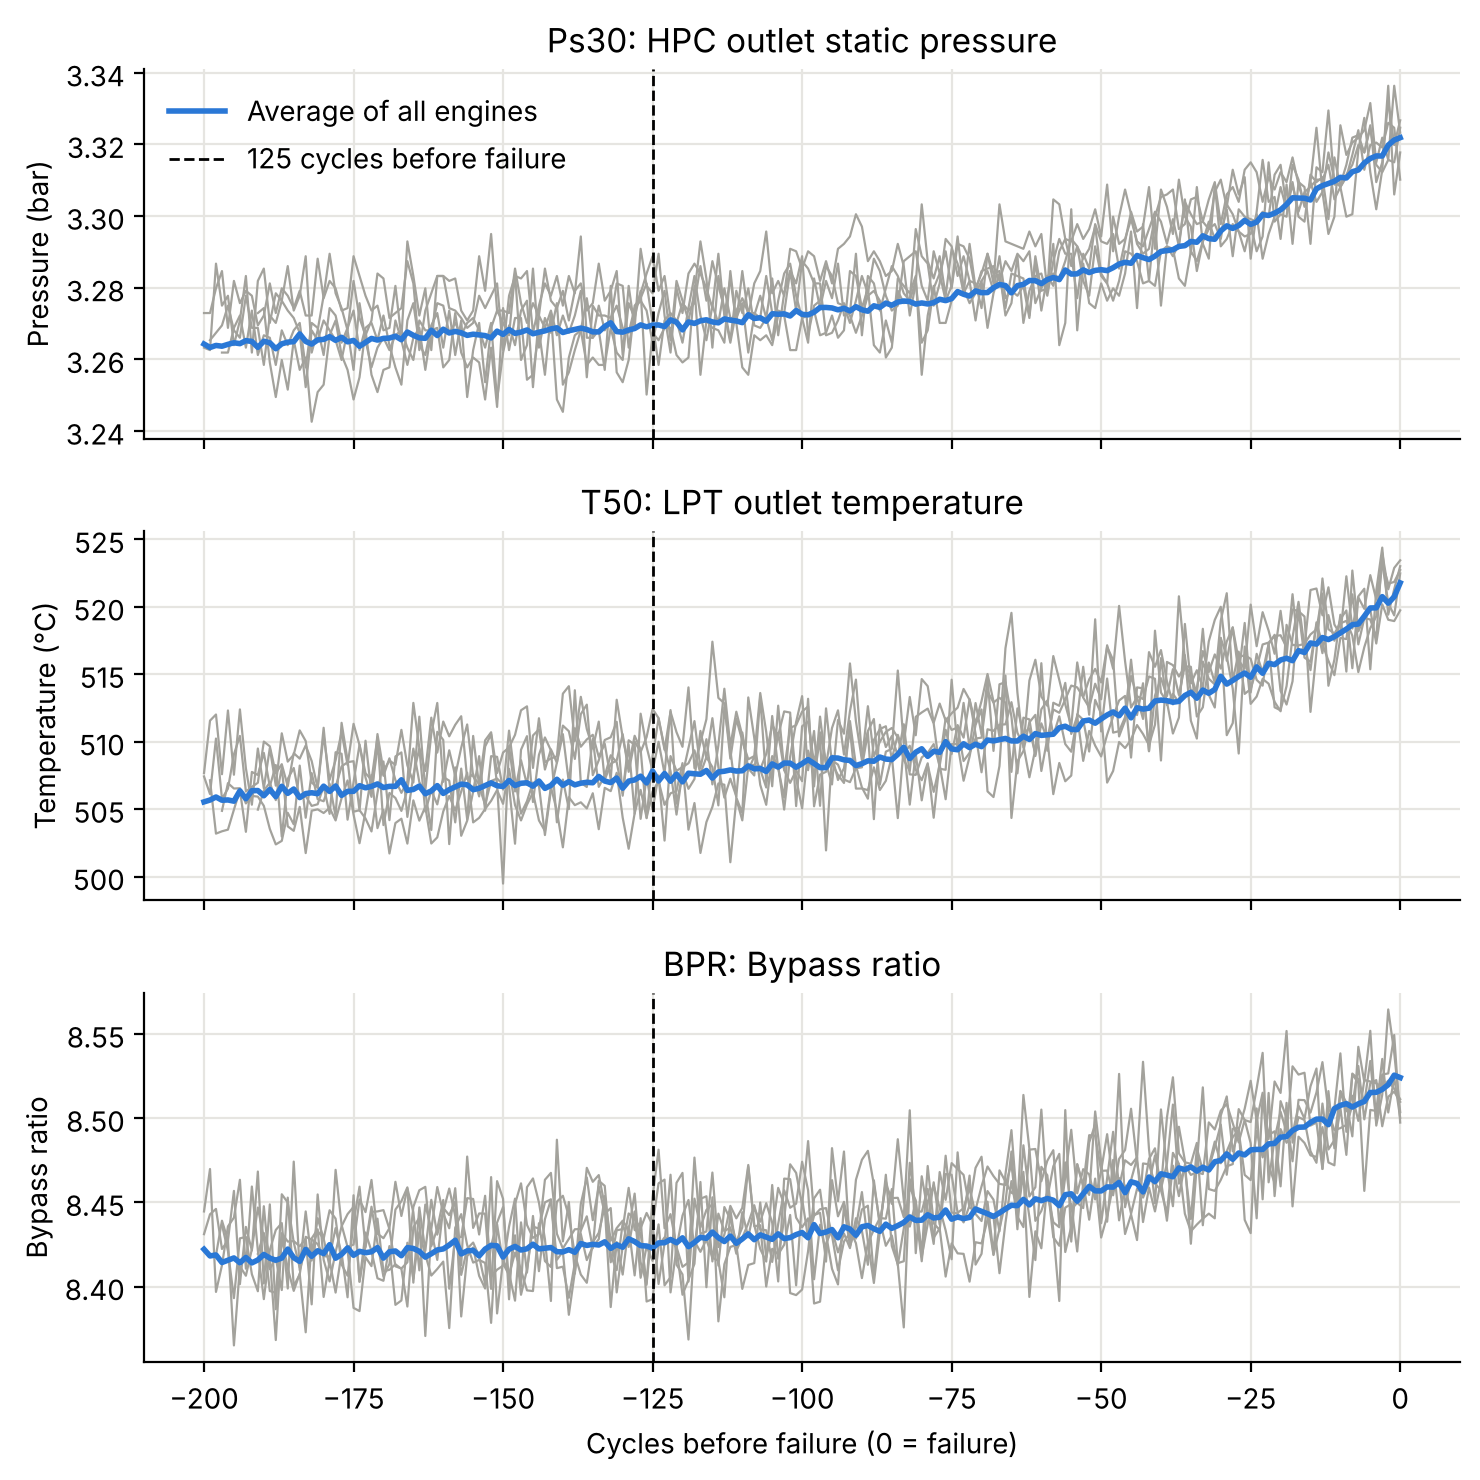

Ps30: 91% of its change over the last 200 cycles happens in the last 125
T50: 86% of its change over the last 200 cycles happens in the last 125
BPR: 99% of its change over the last 200 cycles happens in the last 125


In [5]:
plot_sensors = ["Ps30", "T50", "BPR"]
y_labels = {"Ps30": "Pressure (bar)", "T50": "Temperature (°C)", "BPR": "Bypass ratio"}
sample_engines = [1, 25, 50, 75, 100]
window = train[train.rul <= 200]
fleet = window.groupby("rul")[plot_sensors].mean()

fig, axes = plt.subplots(3, 1, figsize=(7.5, 7.5), sharex=True)
for ax, s in zip(axes, plot_sensors):
    for e in sample_engines:
        one = window[window.engine == e]
        ax.plot(-one.rul, one[s], color=GREY, linewidth=0.8)
    ax.plot(-fleet.index, fleet[s], color=BLUE, linewidth=2, label="Average of all engines")
    ax.axvline(-125, color="black", linestyle="--", linewidth=1, label="125 cycles before failure")
    ax.set_title(f"{s}: {LABELS[s]}")
    ax.set_ylabel(y_labels[s])
axes[0].legend(loc="upper left")
axes[2].set_xlabel("Cycles before failure (0 = failure)")
fig.tight_layout()
fig.savefig("figures/sensor_trends.png", dpi=150)
plt.show()

for s in plot_sensors:
    start, before, end = fleet[s].loc[200], fleet[s].loc[125], fleet[s].loc[0]
    share = (end - before) / (end - start) * 100
    print(f"{s}: {share:.0f}% of its change over the last 200 cycles happens in the last 125")

**What this shows:** for most of an engine's life the sensors stay almost flat and noisy. The clear drift only starts in roughly the last 100 to 150 cycles. So a sensor reading can tell "close to failure" from "healthy", but it cannot tell 300 cycles left from 200.

That is why, for the model, I cap the target at 125 cycles: any engine with more than 125 cycles left is simply "healthy, 125+". This cap is a common choice for this data set.

## 5. Estimate the cycles left

Inputs: the 14 sensors at the current cycle. Target: cycles left, capped at 125. I train on the 100 training engines and test on the 100 test engines, using the last recorded cycle of each test engine and NASA's true answers.

I compare a simple linear regression with a random forest.

In [6]:
X = train[sensors]
y = train["rul"].clip(upper=125)
last = test.groupby("engine").tail(1)

models = {
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1),
}
results = []
predictions = {}
for name, model in models.items():
    model.fit(X, y)
    pred = model.predict(last[sensors])
    predictions[name] = pred
    results.append({
        "model": name,
        "RMSE (cycles)": round(root_mean_squared_error(test_rul, pred), 1),
        "MAE (cycles)": round(mean_absolute_error(test_rul, pred), 1),
    })
results = pd.DataFrame(results)
results

,model,RMSE (cycles),MAE (cycles)
0,Linear regression,21.9,17.6
1,Random forest,18.4,13.4


75% of test engines are predicted within 20 cycles of the truth
16 engines get more than 20 extra cycles (the risky case: maintenance would come too late)


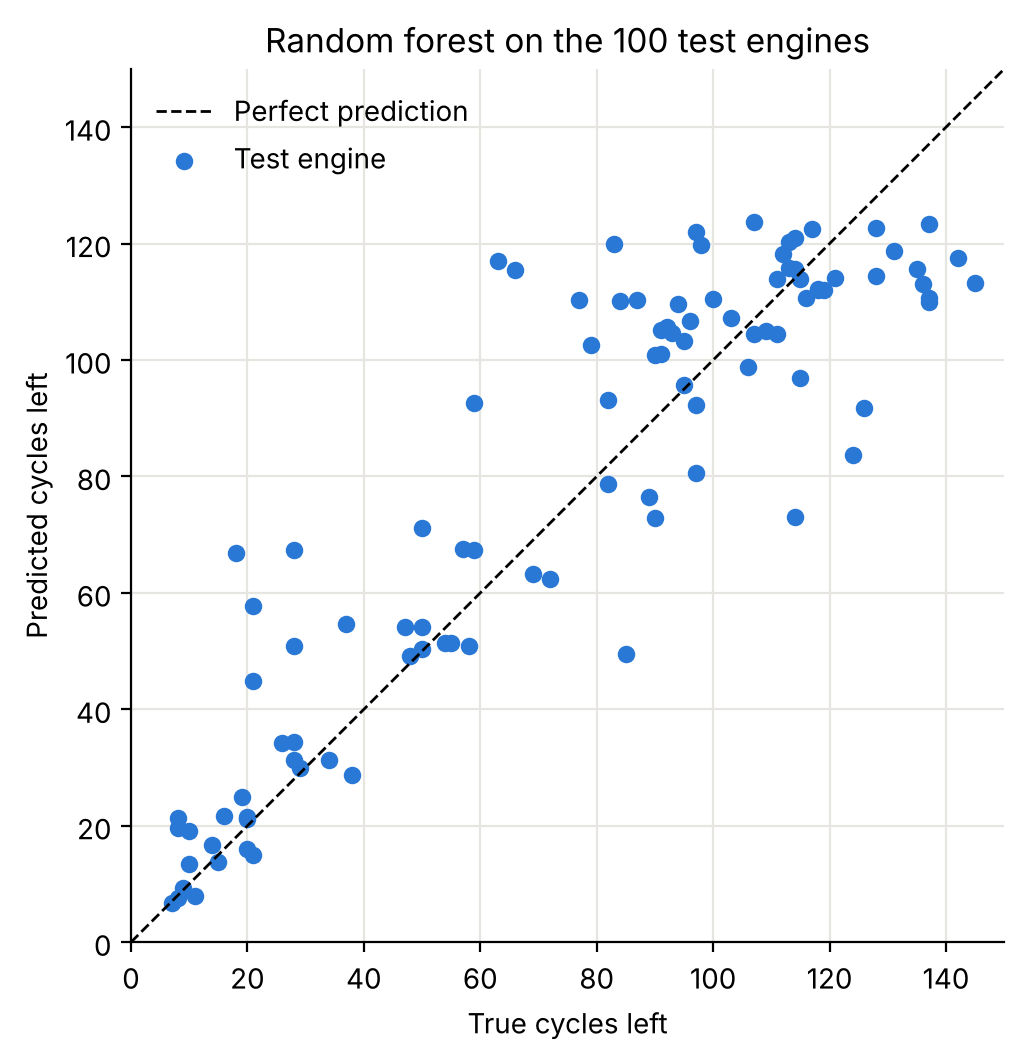

In [7]:
pred = predictions["Random forest"]
errors = pred - test_rul
within_20 = (errors.abs() <= 20).mean() * 100
too_high = (errors > 20).sum()
print(f"{within_20:.0f}% of test engines are predicted within 20 cycles of the truth")
print(f"{too_high} engines get more than 20 extra cycles (the risky case: maintenance would come too late)")

fig, ax = plt.subplots(figsize=(5.8, 5.4))
ax.plot([0, 150], [0, 150], color="black", linestyle="--", linewidth=1, label="Perfect prediction")
ax.scatter(test_rul, pred, s=28, color=BLUE, label="Test engine")
ax.set_xlim(0, 150)
ax.set_ylim(0, 150)
ax.set_aspect("equal")
ax.set_xlabel("True cycles left")
ax.set_ylabel("Predicted cycles left")
ax.set_title("Random forest on the 100 test engines")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig("figures/predicted_vs_true.png", dpi=150)
plt.show()

## 6. Conclusions

- 7 of the 21 sensors never change in this data set and can be dropped, which leaves 14.
- The sensors that follow wear best are the HPC outlet static pressure (Ps30), the LPT outlet temperature (T50) and the fuel flow ratio (phi). Ps30, T50 and the bypass ratio rise as the engine wears, while phi, P30 and the two coolant bleeds fall.
- 86% to 99% of the drift in Ps30, T50 and BPR over the last 200 cycles happens in the last 125, so the sensors are good at spotting an engine close to failure, not at planning far ahead.
- The random forest estimates the cycles left with an average error of 13.4 cycles (RMSE 18.4), against 17.6 (RMSE 21.9) for the linear regression. 75% of the test engines are within 20 cycles of the truth, and the estimates are closest for engines near failure, which is where they matter most.
- 16 engines get more than 20 extra cycles. In real use these are the dangerous errors, so the next step would be to make the model more careful, for example by subtracting a safety margin.

**Limits:** this is simulated data from one operating condition and one fault type (FD001). Real engines run under changing conditions, so the sensors would first need to be normalised per condition.